
# Datheon Internship — Task 02

# Real Estate Housing Price Prediction
## OLS, Ridge and Lasso Regression

### Project Overview

This project develops an end-to-end machine learning regression pipeline to predict median housing prices using the California Housing dataset.

The project focuses on data preprocessing, feature engineering, multicollinearity analysis, regularization, hyperparameter optimization, and model evaluation.

### Objectives

1. Explore and clean the housing dataset.
2. Handle missing values and categorical variables.
3. Engineer meaningful housing-related features.
4. Analyze feature correlations and multicollinearity.
5. Build leakage-safe preprocessing pipelines.
6. Train Ordinary Least Squares, Ridge, and Lasso models.
7. Optimize regularization hyperparameters using GridSearchCV.
8. Compare models using MAE, RMSE, and R².
9. Visualize predictions and residual errors.

### Technologies

Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn

**Dataset:** California Housing CSV

**Target:** median_house_value

## Step 01 - Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 02 - Load Housing Dataset

In [5]:
df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Step 03 - Data Inspection

In [6]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


Duplicate Rows: 0

Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


## Step 04 - Exploratory Data Analysis (EDA)

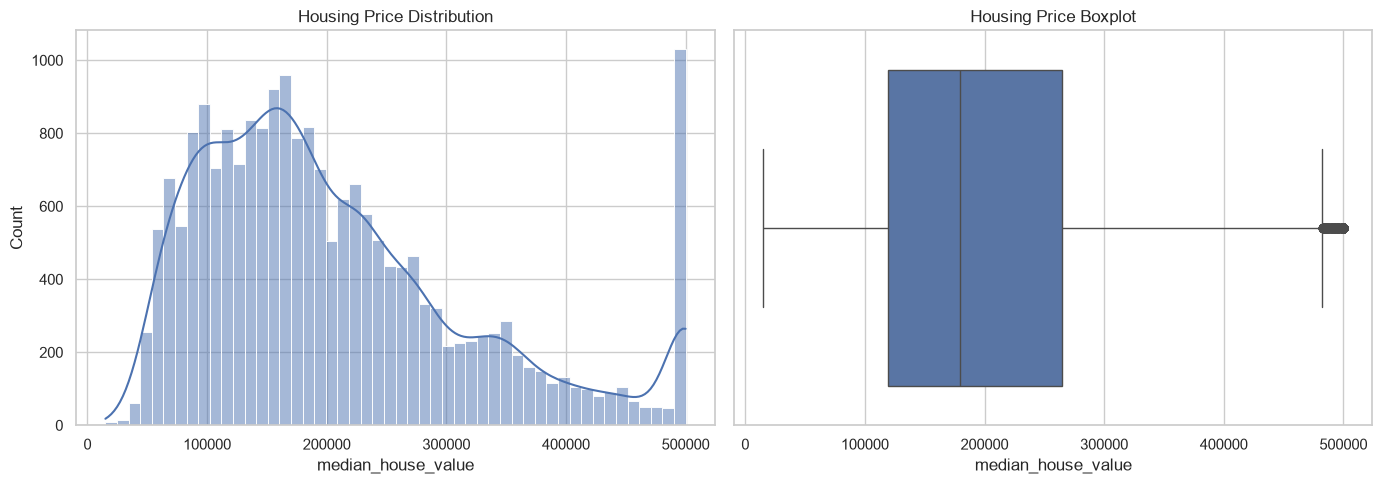

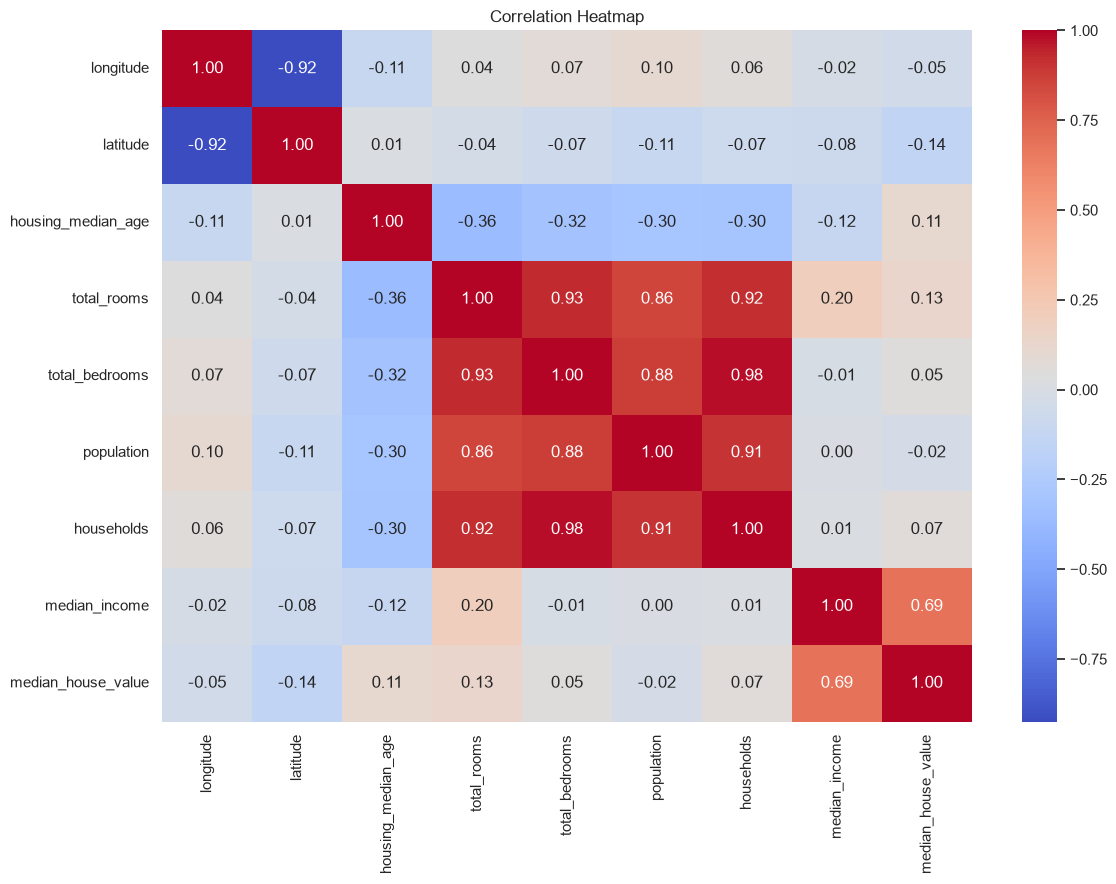

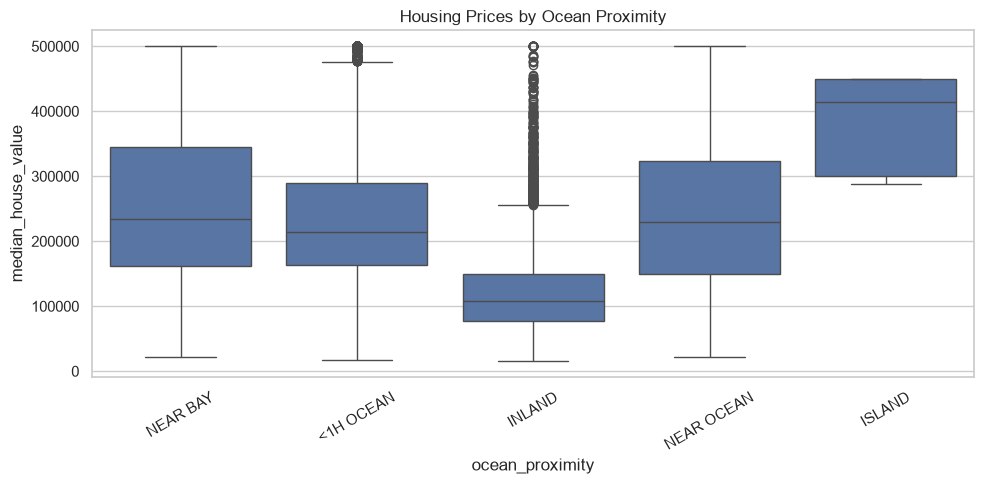

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Housing Price Distribution")

sns.boxplot(
    x=df["median_house_value"],
    ax=axes[1]
)
axes[1].set_title("Housing Price Boxplot")

plt.tight_layout()
plt.show()

numeric_columns = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 9))
sns.heatmap(
    numeric_columns.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value"
)
plt.xticks(rotation=30)
plt.title("Housing Prices by Ocean Proximity")
plt.tight_layout()
plt.show()

## Step 05 - Train-Test Split

In [8]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 9)
Testing Data: (4128, 9)


## Step 06 - Feature Engineering

In [9]:
class HousingFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        households = X["households"].replace(0, np.nan)
        total_rooms = X["total_rooms"].replace(0, np.nan)

        X["rooms_per_household"] = (
            X["total_rooms"] / households
        )

        X["bedrooms_per_room"] = (
            X["total_bedrooms"] / total_rooms
        )

        X["population_per_household"] = (
            X["population"] / households
        )

        X["income_rooms_interaction"] = (
            X["median_income"] * X["rooms_per_household"]
        )

        return X.replace([np.inf, -np.inf], np.nan)


feature_engineer = HousingFeatureEngineer()

X_train_engineered = feature_engineer.fit_transform(X_train)

print("Original Features:", X_train.shape[1])
print("Engineered Features:", X_train_engineered.shape[1])

display(X_train_engineered.head())

Original Features: 9
Engineered Features: 13


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_rooms_interaction
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,NEAR OCEAN,5.017657,0.200576,3.691814,16.355553
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,NEAR OCEAN,4.473545,0.232703,1.738095,17.055390
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,NEAR OCEAN,5.645833,0.174486,2.723214,23.465777
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,NEAR OCEAN,4.002817,0.258269,3.994366,7.775472
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,INLAND,6.268421,0.180940,2.300000,22.279222


## Step 07 - Multicollinearity Analysis

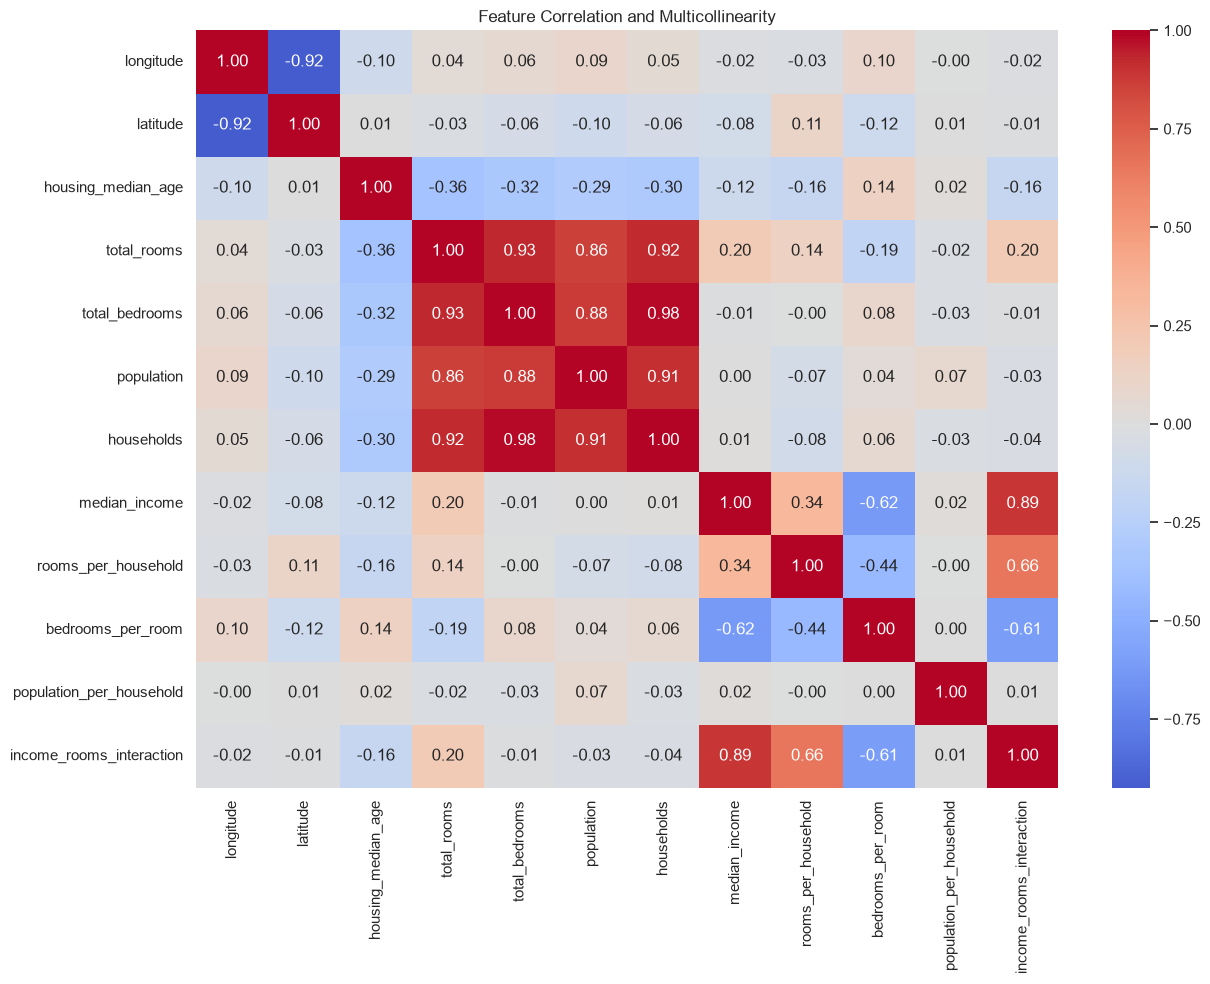

,Feature,VIF
4,total_bedrooms,49.937708
6,households,47.027511
3,total_rooms,18.818198
11,income_rooms_interaction,17.799747
7,median_income,13.693676
1,latitude,9.519946
0,longitude,9.172626
5,population,6.871230
8,rooms_per_household,4.504011
9,bedrooms_per_room,2.894908


In [10]:
numeric_train = X_train_engineered.select_dtypes(include=np.number)

plt.figure(figsize=(13, 10))

sns.heatmap(
    numeric_train.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation and Multicollinearity")
plt.tight_layout()
plt.show()

vif_data = numeric_train.replace(
    [np.inf, -np.inf], np.nan
).copy()

vif_data = vif_data.fillna(vif_data.median())

vif_results = []

for column in vif_data.columns:
    predictors = vif_data.drop(columns=[column])
    target = vif_data[column]

    vif_model = LinearRegression()
    vif_model.fit(predictors, target)

    r2 = vif_model.score(predictors, target)

    vif = 1 / (1 - r2) if r2 < 1 - 1e-10 else np.inf

    vif_results.append({
        "Feature": column,
        "VIF": vif
    })

vif_df = pd.DataFrame(vif_results)

display(vif_df.sort_values("VIF", ascending=False))

## Step 08 - Data Preprocessing Pipeline

In [11]:
numeric_features = X_train_engineered.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_engineered.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)
print("Preprocessing Pipeline Created!")

Numerical Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_rooms_interaction']
Categorical Features: ['ocean_proximity']
Preprocessing Pipeline Created!


## Step 09 - Model Training

In [12]:
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=50000)
}

pipelines = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("feature_engineering", HousingFeatureEngineer()),
        ("preprocessing", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline

    print(f"{name} trained successfully!")

print("\nAll regression models trained!")

OLS trained successfully!
Ridge trained successfully!
Lasso trained successfully!

All regression models trained!


## Step 10 - Hyperparameter Tuning

In [13]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grids = {
    "Ridge": {
        "model__alpha": [0.1, 1, 10, 100, 1000]
    },
    "Lasso": {
        "model__alpha": [0.01, 0.1, 1, 10, 100]
    }
}

best_models = {
    "OLS": pipelines["OLS"]
}

cv_results = []

for name in ["Ridge", "Lasso"]:

    grid = GridSearchCV(
        estimator=pipelines[name],
        param_grid=param_grids[name],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    cv_results.append({
        "Model": name,
        "Best Alpha": grid.best_params_["model__alpha"],
        "CV RMSE": -grid.best_score_
    })

    print(f"\n{name}")
    print("Best Parameters:", grid.best_params_)
    print("Cross-Validation RMSE:", round(-grid.best_score_, 2))

display(pd.DataFrame(cv_results))

print("Hyperparameter tuning completed!")


Ridge
Best Parameters: {'model__alpha': 10}
Cross-Validation RMSE: 67768.06

Lasso
Best Parameters: {'model__alpha': 100}
Cross-Validation RMSE: 67768.24


,Model,Best Alpha,CV RMSE
0,Ridge,10,67768.061997
1,Lasso,100,67768.236916


Hyperparameter tuning completed!


## Step 11 - Model Evaluation (MAE, RMSE, R2)

In [14]:
results = []
predictions = {}

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE")

print("Model Performance Comparison:")
display(results_df.round(4))

Model Performance Comparison:


,Model,MAE,RMSE,R2 Score
0,OLS,49709.5395,68917.3167,0.6375
1,Ridge,49727.5672,68968.3046,0.6370
2,Lasso,49691.6924,69003.1308,0.6366


## Step 12 - Model Performance Visualization

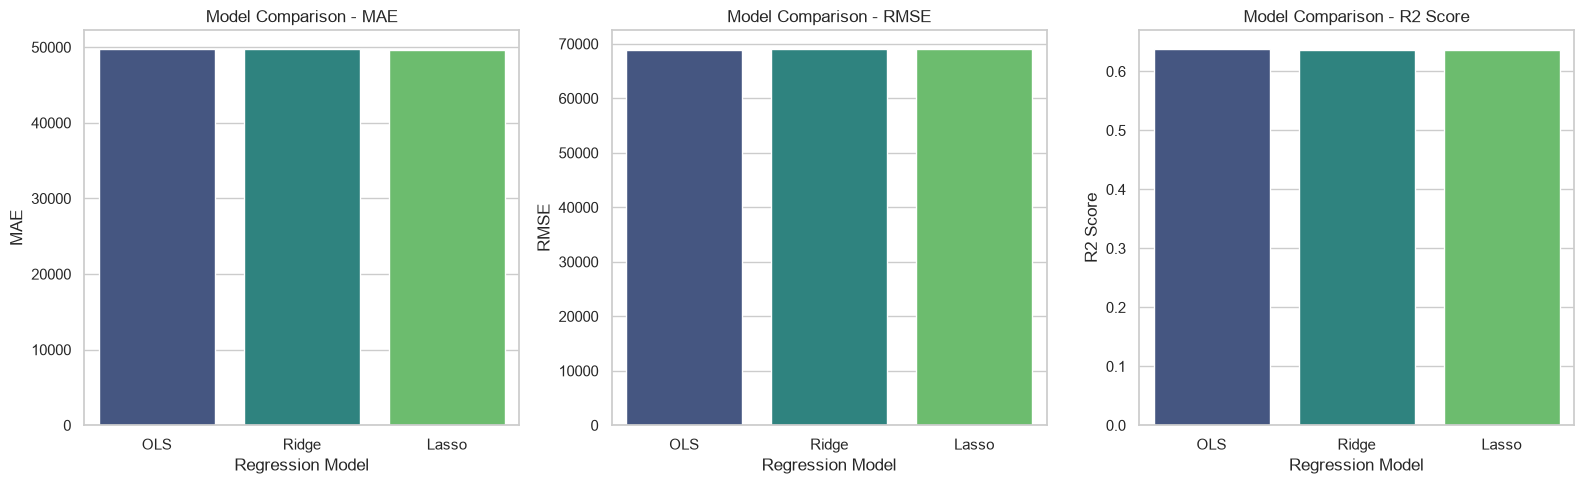

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["MAE", "RMSE", "R2 Score"]

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        hue="Model",
        palette="viridis",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Model Comparison - {metric}")
    ax.set_xlabel("Regression Model")
    ax.set_ylabel(metric)

plt.tight_layout()
plt.show()

## Step 13 - Actual vs Predicted Housing Prices

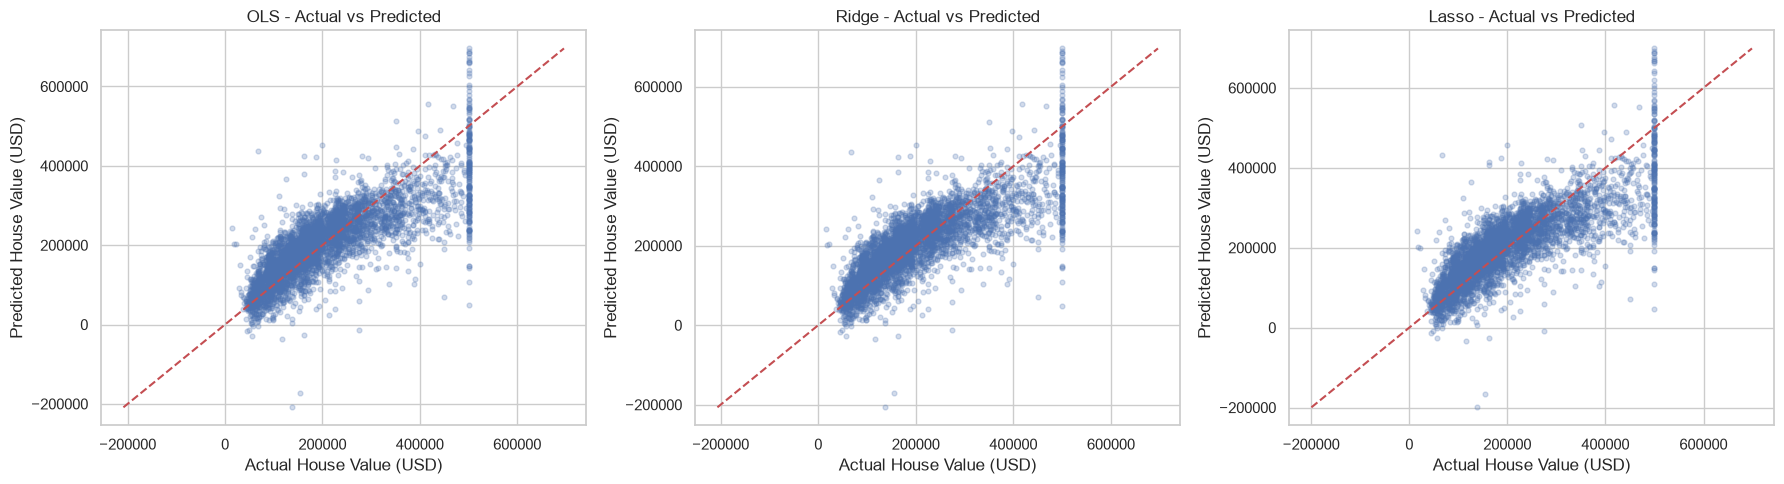

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(
    axes, predictions.items()
):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.25,
        s=12
    )

    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--"
    )

    ax.set_title(f"{name} - Actual vs Predicted")
    ax.set_xlabel("Actual House Value (USD)")
    ax.set_ylabel("Predicted House Value (USD)")

plt.tight_layout()
plt.show()

## Step 14 - Residual Error Analysis

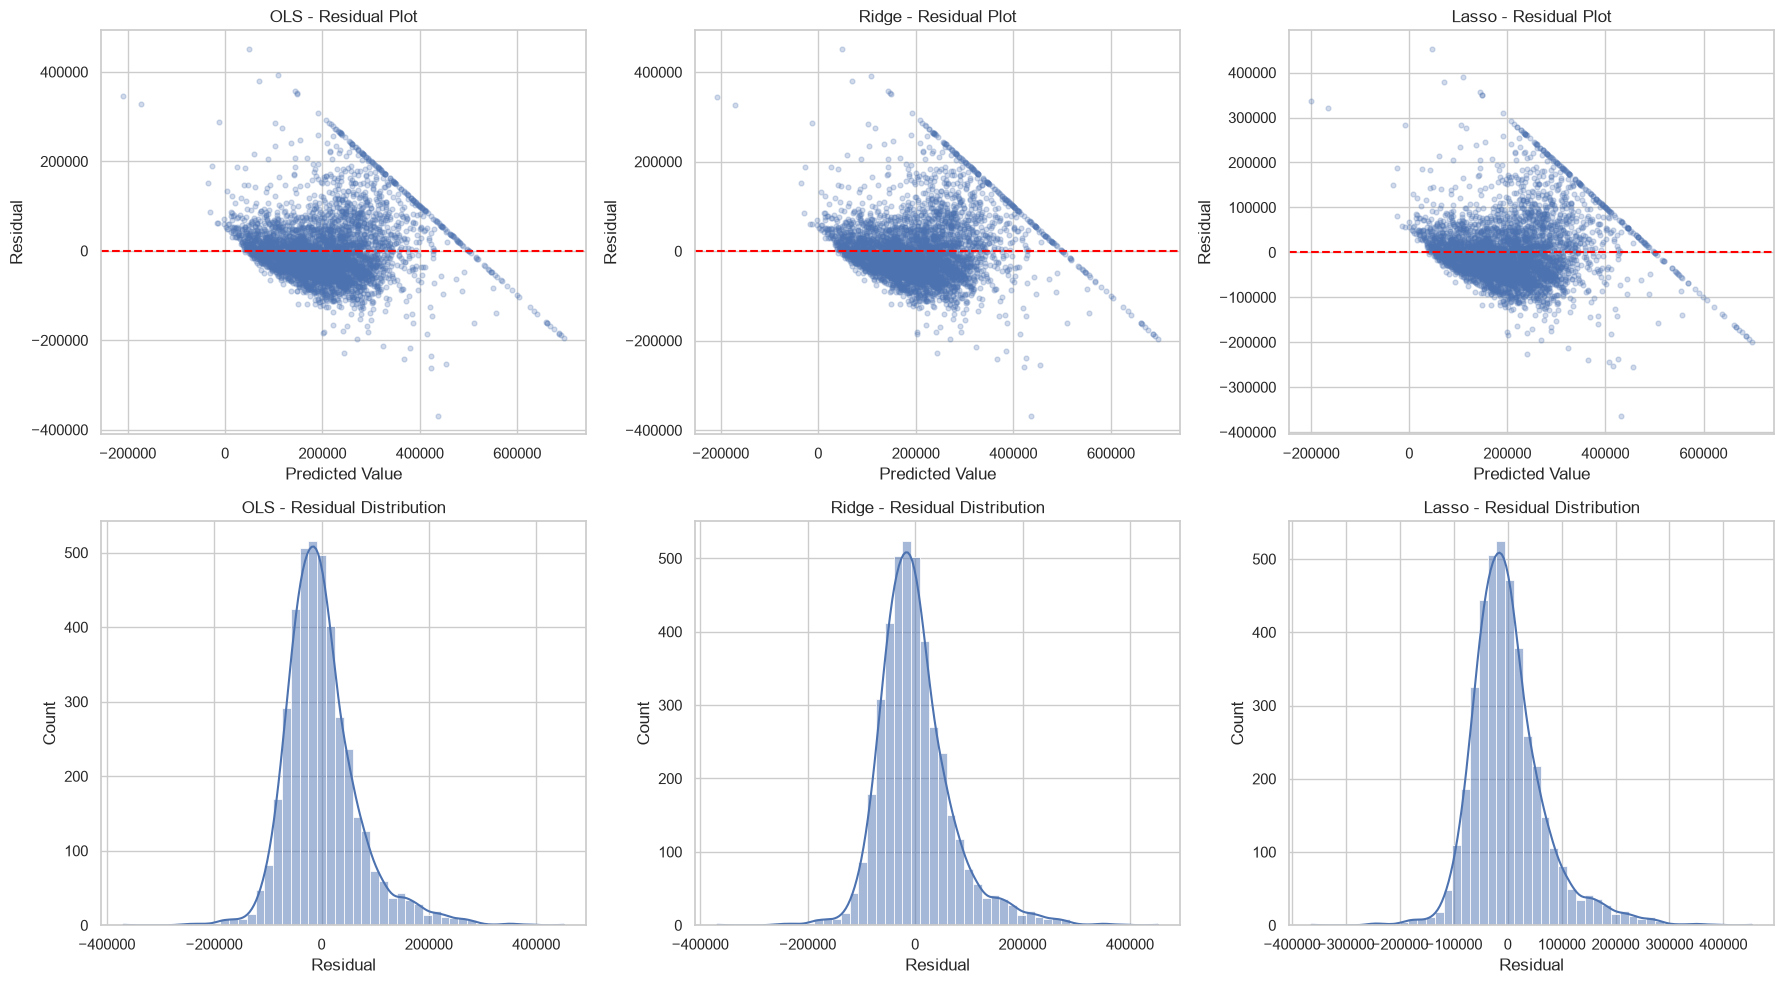

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, (name, y_pred) in enumerate(predictions.items()):

    residuals = y_test.to_numpy() - y_pred

    axes[0, i].scatter(
        y_pred,
        residuals,
        alpha=0.25,
        s=12
    )

    axes[0, i].axhline(
        y=0,
        color="red",
        linestyle="--"
    )

    axes[0, i].set_title(f"{name} - Residual Plot")
    axes[0, i].set_xlabel("Predicted Value")
    axes[0, i].set_ylabel("Residual")

    sns.histplot(
        residuals,
        bins=50,
        kde=True,
        ax=axes[1, i]
    )

    axes[1, i].set_title(f"{name} - Residual Distribution")
    axes[1, i].set_xlabel("Residual")

plt.tight_layout()
plt.show()

## Step 15 - Regression Coefficient Comparison

Regression Coefficients:


,OLS,Ridge,Lasso
numeric__longitude,-55498.4345,-54745.4571,-53177.9803
numeric__latitude,-55796.5841,-55024.6970,-53649.7332
numeric__housing_median_age,14260.7815,14282.7285,14098.3860
numeric__total_rooms,7124.0090,6997.0413,5905.6777
numeric__total_bedrooms,6998.9713,7764.6678,8039.7723
numeric__population,-45386.6715,-45094.1063,-44157.5481
numeric__households,36348.7166,35439.3500,35239.3240
numeric__median_income,92154.7329,91442.3530,89303.6293
numeric__rooms_per_household,14106.8740,13648.5459,12340.4627
numeric__bedrooms_per_room,18206.9828,18048.2919,17520.9924


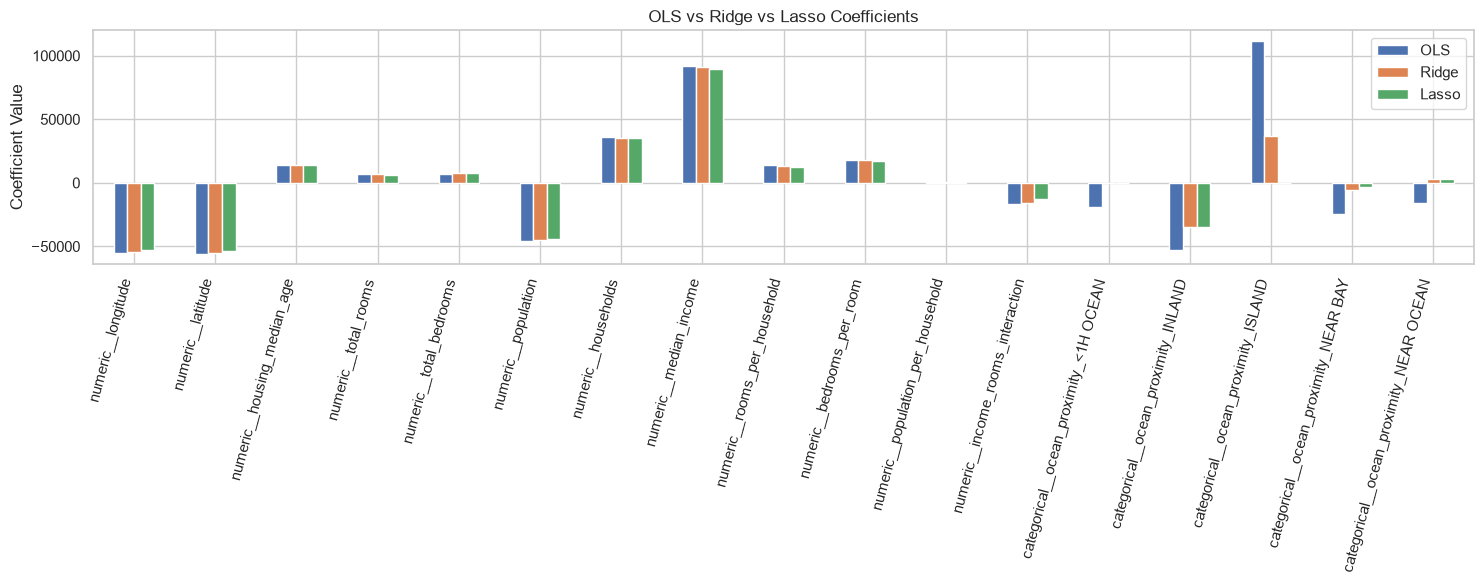

In [18]:
coefficient_data = {}

for name, pipeline in best_models.items():

    feature_names = (
        pipeline.named_steps["preprocessing"]
        .get_feature_names_out()
    )

    coefficients = pipeline.named_steps["model"].coef_

    coefficient_data[name] = pd.Series(
        coefficients,
        index=feature_names
    )

coefficient_df = pd.DataFrame(coefficient_data)

print("Regression Coefficients:")
display(coefficient_df.round(4))

coefficient_df.plot(
    kind="bar",
    figsize=(15, 6)
)

plt.title("OLS vs Ridge vs Lasso Coefficients")
plt.ylabel("Coefficient Value")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

## Step 16 - Final Results and Conclusion

In [19]:
best_row = results_df.iloc[0]

print("=" * 55)
print("DATHEON INTERNSHIP - TASK 02")
print("HOUSING PRICE PREDICTION")
print("=" * 55)

display(results_df.round(4))

print("\nLowest Test RMSE Model:", best_row["Model"])
print("MAE:", round(best_row["MAE"], 2))
print("RMSE:", round(best_row["RMSE"], 2))
print("R2 Score:", round(best_row["R2 Score"], 4))

print("\nTask 02 execution completed!")

DATHEON INTERNSHIP - TASK 02
HOUSING PRICE PREDICTION


,Model,MAE,RMSE,R2 Score
0,OLS,49709.5395,68917.3167,0.6375
1,Ridge,49727.5672,68968.3046,0.6370
2,Lasso,49691.6924,69003.1308,0.6366



Lowest Test RMSE Model: OLS
MAE: 49709.54
RMSE: 68917.32
R2 Score: 0.6375

Task 02 execution completed!


## Final Conclusion — Task 02

### Project Summary
Successfully developed an end-to-end California Housing Price Prediction pipeline using OLS, Ridge, and Lasso Regression.

### Model Performance

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| OLS | 49,709.54 | 68,917.32 | 0.6375 |
| Ridge | 49,727.57 | 68,968.30 | 0.6370 |
| Lasso | 49,691.69 | 69,003.13 | 0.6366 |

### Key Findings
- **Lowest RMSE:** OLS Regression ($68,917.32).
- **Lowest MAE:** Lasso Regression ($49,691.69).
- **Best R²:** OLS Regression (0.6375).
- **Feature Engineering:** Created four additional features.
- **Regularization:** Ridge and Lasso addressed multicollinearity through coefficient regularization.
- **Limitations:** High-value properties showed larger prediction errors, and some predictions were negative.

### Final Outcome
OLS achieved the lowest test RMSE, while all three models demonstrated similar predictive performance. The project successfully implemented data preprocessing, feature engineering, hyperparameter tuning, model evaluation, and residual analysis.

**Project Status:** Completed  
**Internship:** Datheon — Machine Learning & Data Science  
**Task:** 02 — Real Estate Housing Price Prediction